# Education Divide: Analyzing the Impact of Infrastructure and Economy on Lower Secondary School Completion (2013–2023)
**Group 36**


*Ian Henriquez (6558887), Aditya Ranalkar (6582044), Idse Wiersma (6208967)*

## Introduction

The SDG our team focused on was education. Since there are some places in the world where the completion of education is not as high as might be desirable, we wanted to look at what factors might have a correlation with people who didn’t complete secondary school. We believe income level for a country plays a big role for the population which completed secondary school, hence it will be integrated early on in our analysis. The chart below illustrates this divide over the past decade, showing why a deeper analysis into the underlying factors is necessary:

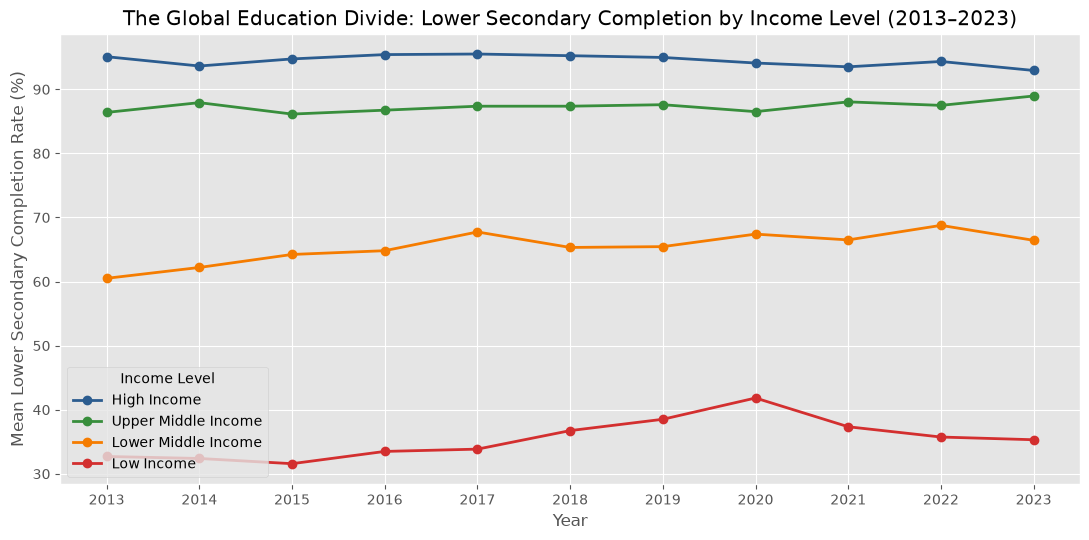

In [38]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wbgapi as wb
import os
import requests
plt.style.use('ggplot')


# show disparity in lower secondary completion rates by level over time
df_intro = pd.read_csv('all_countries_data.csv')
df_intro['Lower_Sec_Completion_Pct'] = df_intro['Lower_Sec_Completion_Pct'].clip(upper=100.0)

income_order = ['High Income', 'Upper Middle Income', 'Lower Middle Income', 'Low Income']
income_colors = {
    'High Income': '#2b5c8f',
    'Upper Middle Income': '#388e3c',
    'Lower Middle Income': '#f57c00',
    'Low Income': '#d32f2f'
}

plt.figure(figsize=(11, 5.5))
for lvl in income_order:
    subset = df_intro[df_intro['Income_Level'] == lvl]
    yearly_edu = subset.groupby('Year')['Lower_Sec_Completion_Pct'].mean()
    plt.plot(
        yearly_edu.index, yearly_edu.values,
        marker='o', linewidth=2, color=income_colors[lvl], label=lvl
    )

plt.title('The Global Education Divide: Lower Secondary Completion by Income Level (2013–2023)')
plt.xlabel('Year')
plt.ylabel('Mean Lower Secondary Completion Rate (%)')
plt.xticks(range(2013, 2024))
plt.legend(title='Income Level')
plt.tight_layout()
plt.show()

As seen above, the gap between the poorest nations and the rest of the world has remained for the most part unchanged. Therefore after establishing this baseline we will look at other factors (internet access, electricity, inflation, and unemployment) that may be contributing to this divide.

**Research Question :**


*What factors affect secondary school completion rates and how has it changed over the last decade?*

## Datasets
The primary datasets were sourced via the World Bank API and exported to CSV format for analytical convenience. The primary dataset included data of secondary school completion rate, internet access, electricity access, income level and income per capita. The primary dataset was accompanied by a secondary dataset collected from the World Bank Economy section. To incorporate necessary financial metrics, inflation rate data was subsequently gathered from the International Monetary Fund (IMF) API and similarly converted into CSV files to ensure streamlined integration into the analysis workflow.


In [39]:
def fetch_world_bank_data(indicators, time_range):
    print("Fetching data from World Bank API...")
    df = wb.data.DataFrame(
        series=indicators.keys(), 
        time=time_range, 
        labels=True, 
        columns='series' 
    ).reset_index()
    
    df = df.rename(columns={'economy': 'Country_Code', 'Country': 'Country_Name', 'time': 'Year'})
    df = df.rename(columns=indicators)
    df = df.drop(columns='Time', errors='ignore')
    df['Year'] = df['Year'].str.replace('YR', '').astype(int)

    df = attach_income(df)
    return df

def attach_income(df):
    #grab economic data from World bank
    countries = wb.economy.DataFrame()
    sovereign_countries = countries[countries['aggregate'] == False]
    sovereign_codes = sovereign_countries.index

    df = df[df['Country_Code'].isin(sovereign_codes)]

    income_map = sovereign_countries['incomeLevel'].to_dict()

    df['Income_Level_Code'] = df['Country_Code'].map(income_map)

    income_names = {
        'HIC': 'High Income',
        'UMC': 'Upper Middle Income',
        'LMC': 'Lower Middle Income',
        'LIC': 'Low Income',
        'INX': 'Not Classified'
    }

    df['Income_Level'] = df['Income_Level_Code'].map(income_names)

    # drop not classified to keep the analysis focused on recognized income levels
    df = df[df['Income_Level'] != 'Not Classified']
    return df

def fetch_imf_data(imf_indicators, time_range):
    base_url = "https://www.imf.org/external/datamapper/api/v1"
    target_years = set(map(str, time_range))
    imf_df = None

    for code, col_name in imf_indicators.items():
        url = f"{base_url}/{code}"
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        data = response.json()

        country_dict = data.get('values', {}).get(code, {})
        records = []

        for country_code, years_data in country_dict.items():
            for year_str, value in years_data.items():
                if year_str in target_years:
                    records.append({
                        'Country_Code': country_code,
                        'Year': int(year_str),
                        col_name: pd.to_numeric(value, errors='coerce')
                    })

        df_indicator = pd.DataFrame(records)
        if imf_df is None:
            imf_df = df_indicator
        else:
            imf_df = pd.merge(imf_df, df_indicator, on=['Country_Code', 'Year'], how='outer')

    return imf_df

if (os.path.isfile('all_countries_data.csv') and os.path.isfile('imf_secondary_data.csv')):
    print('reading CSV.....')
    df_wb = pd.read_csv('all_countries_data.csv', delimiter=',')
    df_imf = pd.read_csv('imf_secondary_data.csv', delimiter=',')
    
else:
    # define the specific World Bank Series Codes
    indicators = {
        'IT.NET.USER.ZS': 'Internet_Usage_Pct',
        'SE.SEC.CMPT.LO.ZS': 'Lower_Sec_Completion_Pct',
        'NY.ADJ.NNTY.PC.CD': 'Income_Per_Capita_USD',
        'EG.ELC.ACCS.ZS': 'Electricity_Access_Pct',
    }

    imf_indicators = {
        'PCPIPCH': 'Inflation_Rate_Pct'
    }
    
    time_range = range(2013, 2024)

    df_wb = fetch_world_bank_data(indicators, time_range)
    df_imf = fetch_imf_data(imf_indicators, time_range)

    #save to csv
    df_imf.to_csv('imf_secondary_data.csv', index=False)
    df_wb.to_csv('all_countries_data.csv', index=False)

    print("\nData fetched successfully!")




reading CSV.....


## Data Preprocessing
A few preprocessing steps were taken before we began the analysis. Because the merged datasets contained aggregate regions and countries, we dropped those aggregates, leaving only sovereign countries in the data frame in order to prevent double counting and ensure our analysis focused only on national outcomes. 

We also noticed that our datasets frequently missed some annual economic data observations. In order to avoid skewing the analysis in favor of countries with more complete observational data, we decided to use per country linear interpolation in order to fill in gaps with estimates based on each country's individual historic trajectory, instead of just using global medians which would distort national trends.

Additionally, secondary completion rates could sometimes go above 100% due to either grade repetition or adult completion, in order to standardize the metric and prevent skewing data we decided to cap it at 100%

Lastly we recognized that some countries experience inflation rates surpassing 100% which is a phenomenon known as hyperinflation. Since this is an extreme that is not the common case for most countries, we masked the top 5% of inflation rates. Allowing affected countries to remain in the dataset for other economic metrics without skewing our analysis. 

In [40]:
def clean_and_merge_data(df, df_imf):
    # merge IMF data with World Bank data
    df = pd.merge(df, df_imf, on=['Country_Code', 'Year'], how='inner')
    df = df.sort_values(['Country_Code', 'Year']).reset_index(drop=True)

    print('missing values before interpolation')
    print(df.isnull().sum()[df.isnull().sum() > 0], "\n")
    wdi_cols = [
        'Lower_Sec_Completion_Pct',
        'Income_Per_Capita_USD',
        'Electricity_Access_Pct',
        'Internet_Usage_Pct'
    ]
    imf_cols = ['Inflation_Rate_Pct']

    # Interpolate missing values within each country
    for col in wdi_cols + imf_cols:
        if col in df.columns:
            df[col] = (
                df.groupby('Country_Code')[col]
                .transform(lambda s: s.interpolate(method='linear').ffill().bfill())
            )

    # Fill remaining World Bank missing values by income level and year
    for col in wdi_cols:
        df[col] = df[col].fillna(
            df.groupby(['Income_Level', 'Year'])[col].transform('median')
        )
        df[col] = df[col].fillna(
            df.groupby('Income_Level')[col].transform('median')
        )

    # Cap percentage columns at 100%
    pct_cols = [
        'Lower_Sec_Completion_Pct',
        'Electricity_Access_Pct',
        'Internet_Usage_Pct'
    ]
    df[pct_cols] = df[pct_cols].clip(upper=100.0)

    # Replace extreme inflation values with missing values
    if 'Inflation_Rate_Pct' in df.columns:
        inf_95 = df['Inflation_Rate_Pct'].quantile(0.95)
        df.loc[
            df['Inflation_Rate_Pct'] >= inf_95,
            'Inflation_Rate_Pct'
        ] = np.nan

        df['Inflation_Rate_Pct'] = (
            df.groupby('Country_Code')['Inflation_Rate_Pct']
            .transform(lambda s: s.interpolate(method='linear').ffill().bfill())
        )

    # Process unemployment only if the column exists
    if 'Unemployment_Rate_Pct' in df.columns:
        unemp_95 = df['Unemployment_Rate_Pct'].quantile(0.95)
        df.loc[
            df['Unemployment_Rate_Pct'] >= unemp_95,
            'Unemployment_Rate_Pct'
        ] = np.nan

    print("Missing values after preprocessing:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    return df

df = clean_and_merge_data(df_wb, df_imf)

missing values before interpolation
Internet_Usage_Pct           99
Income_Per_Capita_USD       551
Lower_Sec_Completion_Pct    717
dtype: int64 

Missing values after preprocessing:
Inflation_Rate_Pct    11
dtype: int64


**Dataset Overview**
Before evaluating the infrastructure and economic factors, it is important to understand the composition of our cleaned dataset. As shown in the chart below, our final dataset of sovereign nations is heavily weighted toward High and Upper Middle Income countries. This context is crucial, as the relatively small sample size of Low-Income countries (N=23) means they are more susceptible to data limitations and missing values

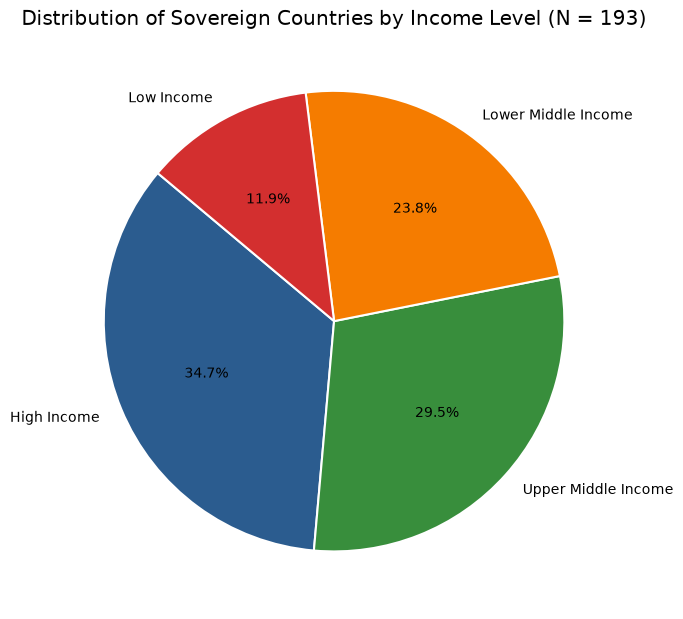

In [41]:
income_order = ['High Income', 'Upper Middle Income', 'Lower Middle Income', 'Low Income']

df_country = (df.groupby(['Country_Code', 'Country_Name', 'Income_Level'], as_index=False).mean(numeric_only=True))

income_colors = {
    'High Income': '#2b5c8f',
    'Upper Middle Income': '#388e3c',
    'Lower Middle Income': '#f57c00',
    'Low Income': '#d32f2f'
}

# Pie chart of how many countries are in each income level
counts = df_country['Income_Level'].value_counts().reindex(income_order)
plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[income_colors[lvl] for lvl in counts.index],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title(f'Distribution of Sovereign Countries by Income Level (N = {counts.sum()})')
plt.tight_layout()
plt.show()

## Data Analysis, Visualization & Discussion
To answer our research question, we decided that we needed to analyze the differences between long-term infrastructure factors (i.e. internet and electricity access) and short term economic changes (i.e. inflation). To do this, we broke our analysis down into three main methods


### Decade Progress Analysis
First, we wanted to see how the baseline gap in education between countries has changed over the last decade. Since education and infrastructure take a long time to change, looking at the 10 year gap (2013 vs. 2023) helped filter out some yearly noise, showing the actual progress being made.

Income_Per_Capita_USD                                \
                                    count      mean       std    median   
Income_Level                                                              
High Income                            67  27769.74  15091.60  24143.58   
Upper Middle Income                    57   5083.10   1708.43   4705.97   
Lower Middle Income                    46   2026.79   1700.90   1667.54   
Low Income                             23    540.22    214.00    529.54   

                    Lower_Sec_Completion_Pct                       \
                                       count   mean    std median   
Income_Level                                                        
High Income                               67  94.32   8.01  97.20   
Upper Middle Income                       57  86.14  13.76  89.75   
Lower Middle Income                       46  63.10  18.23  63.40   
Low Income                                23  34.78  13.19  33.06   

                    Internet_Usage_Pct                       \
                                 count   mean    std median   
Income_Level                                                  
High Income                         67  83.13  10.10  84.00   
Upper Middle Income                 57  57.88  14.64  60.69   
Lower Middle Income                 46  34.97  16.11  30.31   
Low Income                          23  12.49   6.25  11.43   

                    Inflation_Rate_Pct                     
                                 count  mean   std median  
Income_Level                                               
High Income                         67  2.41  1.35   2.25  
Upper Middle Income                 57  4.23  2.81   3.62  
Lower Middle Income                 45  5.63  3.43   5.00  
Low Income                          23  6.40  5.44   5.38

,Edu_2013 (%),Edu_2023 (%),Edu_Change (+pp),Internet_2013 (%),Internet_2023 (%),Internet_Change (+pp),Elec_2013 (%),Elec_2023 (%),Elec_Change (+pp)
Income_Level,,,,,,,,,
High Income,94.92,94.21,-0.71,73.31,90.95,17.64,99.45,99.92,0.47
Upper Middle Income,84.98,87.10,2.13,37.62,75.33,37.71,94.16,97.58,3.42
Lower Middle Income,59.72,65.56,5.84,16.72,52.75,36.03,62.78,78.58,15.80
Low Income,31.72,33.58,1.86,4.42,20.83,16.41,23.18,40.34,17.16


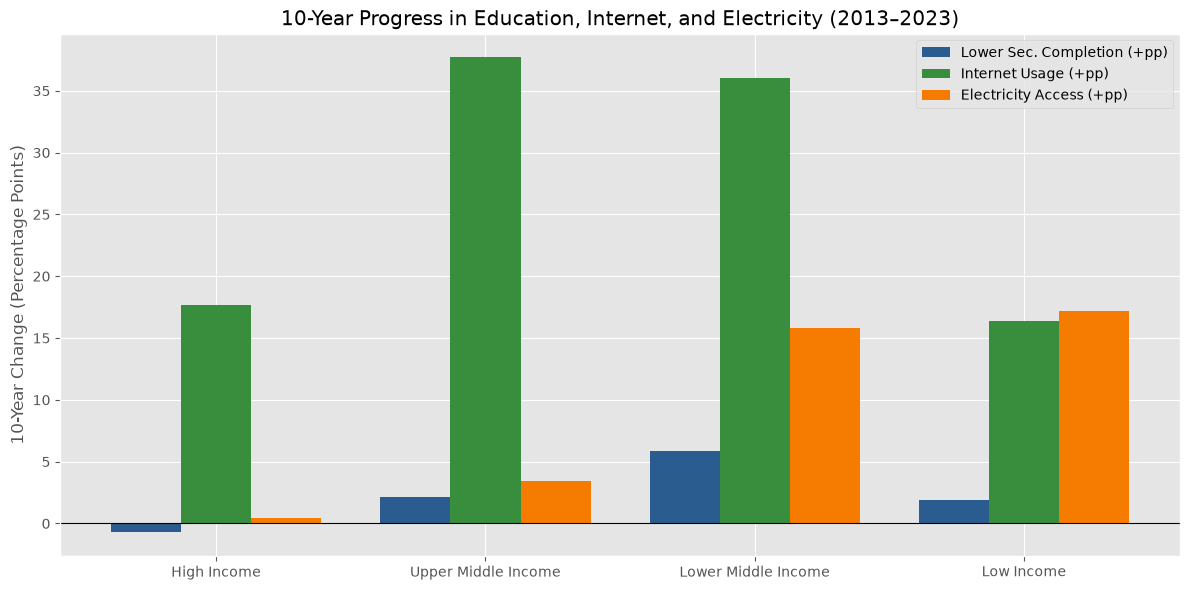

In [42]:
def summarize_by_income(df, value_col):
    return (df.groupby('Income_Level')[value_col].agg(['count', 'mean', 'std', 'median']).reindex(income_order)).round(2)

def progress_per_year(data):

    # compare 2013 vs 2023 for key indicators and calculate the change for each income level
    cols = ['Lower_Sec_Completion_Pct', 'Internet_Usage_Pct', 'Electricity_Access_Pct']
    d_2013 = data[data['Year'] == 2013].groupby('Income_Level')[cols].mean().reindex(income_order)
    d_2023 = data[data['Year'] == 2023].groupby('Income_Level')[cols].mean().reindex(income_order)

    progress = pd.DataFrame({
        'Edu_2013 (%)': d_2013['Lower_Sec_Completion_Pct'],
        'Edu_2023 (%)': d_2023['Lower_Sec_Completion_Pct'],
        'Edu_Change (+pp)': d_2023['Lower_Sec_Completion_Pct'] - d_2013['Lower_Sec_Completion_Pct'],
        'Internet_2013 (%)': d_2013['Internet_Usage_Pct'],
        'Internet_2023 (%)': d_2023['Internet_Usage_Pct'],
        'Internet_Change (+pp)': d_2023['Internet_Usage_Pct'] - d_2013['Internet_Usage_Pct'],
        'Elec_2013 (%)': d_2013['Electricity_Access_Pct'],
        'Elec_2023 (%)': d_2023['Electricity_Access_Pct'],
        'Elec_Change (+pp)': d_2023['Electricity_Access_Pct'] - d_2013['Electricity_Access_Pct']
    }).round(2)
    return progress

def plot_decade_progress(data):
    metrics = {
        'Edu': 'Lower_Sec_Completion_Pct',
        'Internet': 'Internet_Usage_Pct',
        'Elec': 'Electricity_Access_Pct'
    }

    period_df = data[data['Year'].isin([2013, 2023])]

    summary = (
        period_df
        .groupby(['Income_Level', 'Year'])[list(metrics.values())]
        .mean()
        .unstack('Year')
        .reindex(income_order)
    )

    changes = pd.DataFrame(index=income_order)

    for name, column in metrics.items():
        changes[f'{name}_Change (+pp)'] = (
            summary[(column, 2023)] - summary[(column, 2013)]
        )

    x_idx = np.arange(len(income_order))
    width = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(
        x_idx - width,
        changes['Edu_Change (+pp)'],
        width,
        label='Lower Sec. Completion (+pp)',
        color='#2b5c8f'
    )
    ax.bar(
        x_idx,
        changes['Internet_Change (+pp)'],
        width,
        label='Internet Usage (+pp)',
        color='#388e3c'
    )
    ax.bar(
        x_idx + width,
        changes['Elec_Change (+pp)'],
        width,
        label='Electricity Access (+pp)',
        color='#f57c00'
    )

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x_idx)
    ax.set_xticklabels(income_order)
    ax.set_ylabel('10-Year Change (Percentage Points)')
    ax.set_title(
        '10-Year Progress in Education, Internet, and Electricity '
        '(2013–2023)'
    )
    ax.legend()
    fig.tight_layout()
    plt.show()

    return changes, fig, ax

main_indicators = [
    'Income_Per_Capita_USD',
    'Lower_Sec_Completion_Pct',
    'Internet_Usage_Pct',
    'Inflation_Rate_Pct'
]

decade_df = progress_per_year(df)
display(summarize_by_income(df_country, main_indicators))
display(decade_df)
decade_df, fig, ax = plot_decade_progress(df)


As seen in the data above, the secondary school completion rate in higher income nations went down slightly from 2013 to 2023 while internet usage went up. A very high percentage of the population in higher income countries already have access to internet and electricity, and the vast majority of higher income countries already have a secondary completion rate of over 90% with a few outliers. This makes it hard to find a correlation between secondary school completion and this factor.

### Global Correlation of Factors
Before breaking the data down into specific income brackets, we calculated a Pearson correlation matrix for our primary variables across the entire dataset. This provides a mathematical baseline for how strongly physical infrastructure, digital access, and macroeconomic factors are associated with secondary school completion globally.

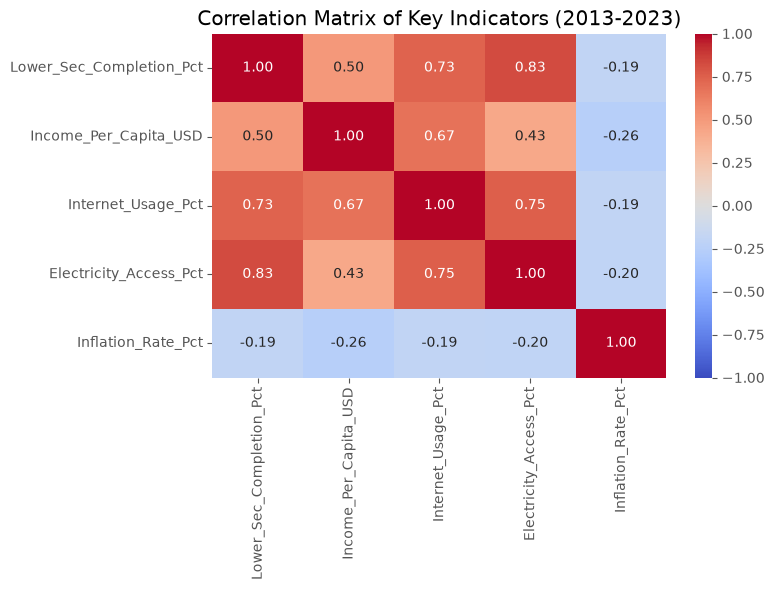

In [ ]:
import seaborn as sns

corr_cols = [
    'Lower_Sec_Completion_Pct', 
    'Income_Per_Capita_USD', 
    'Internet_Usage_Pct', 
    'Electricity_Access_Pct', 
    'Inflation_Rate_Pct'
]

# Calculate the correlation matrix
corr_matrix = df[corr_cols].corr()

# Generate the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True,         
    cmap='coolwarm',    
    fmt=".2f",           
    vmin=-1, vmax=1      
)
plt.title('Correlation Matrix of Key Indicators (2013-2023)')
plt.tight_layout()
plt.show()

The heatmap reveals a strong positive correlation between Electricity Access ($r = 0.83$) and Secondary Completion, as well as Internet Usage ($r = 0.73$). Conversely, Inflation Rate shows a slight negative correlation ($r = -0.19$). However, because Income Per Capita is also highly correlated with both digital ($r = 0.67$) and physical ($r = 0.43$) infrastructure metrics, we must isolate our low-income nations to see if infrastructure makes an independent impact outside of overall national wealth.

## Splitting Low Income Nations by Median Internet Usage
Because of this ceiling effect in high income nations, we wanted to understand how infrastructure affects educational results independent of the wealth of a nation. To do this, we looked exclusively at low income countries and split them into two groups: those with an above median internet usage rate and those below. This way, we could control for extreme poverty and see if digital and physical infrastructure actually make an independent difference for secondary school completion.

,Internet_Usage_Pct,Electricity_Access_Pct,Lower_Sec_Completion_Pct,Income_Per_Capita_USD
Internet_Tier,,,,
Above Median Internet (>= 11.4%),17.02,43.58,40.01,611.50
Below Median Internet (< 11.4%),7.54,22.62,29.09,462.47


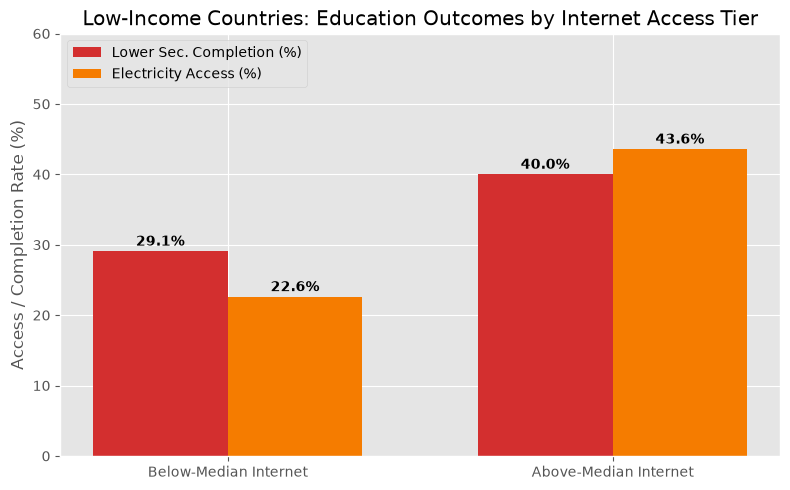

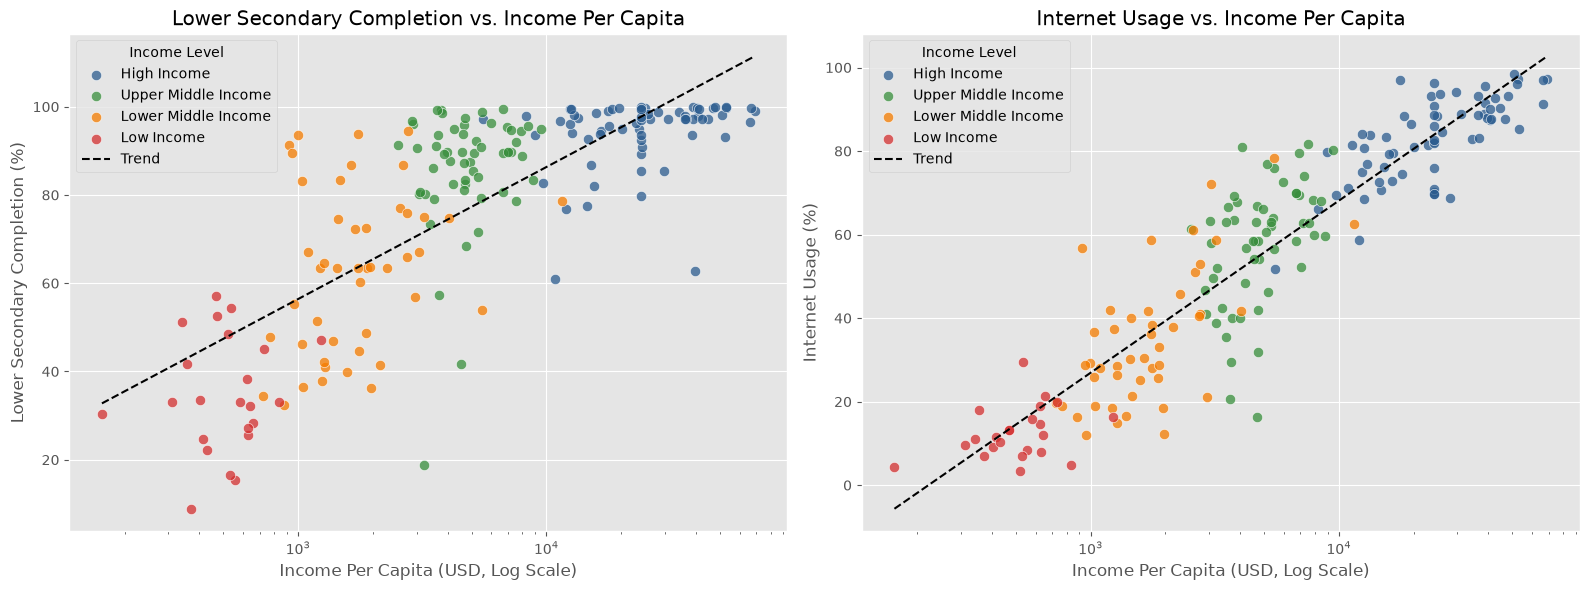

In [46]:
def compare_low_income_internet_tiers(data_country):
     # split low income countries and compare
    low_inc = data_country[data_country['Income_Level'] == 'Low Income'].copy()
    med_net = low_inc['Internet_Usage_Pct'].median()
    low_inc['Internet_Tier'] = np.where(
        low_inc['Internet_Usage_Pct'] >= med_net,
        f'Above Median Internet (>= {med_net:.1f}%)',
        f'Below Median Internet (< {med_net:.1f}%)'
    )
    cols = ['Internet_Usage_Pct', 'Electricity_Access_Pct', 'Lower_Sec_Completion_Pct', 'Income_Per_Capita_USD']
    return low_inc.groupby('Internet_Tier')[cols].mean().round(2)

def plot_low_income_internet_tiers(data_country):
    low_inc = data_country[
        data_country['Income_Level'] == 'Low Income'
    ].copy()

    med_net = low_inc['Internet_Usage_Pct'].median()
    low_inc['Internet_Tier'] = np.where(
        low_inc['Internet_Usage_Pct'] >= med_net,
        'Above-Median Internet',
        'Below-Median Internet'
    )

    tier_order = ['Below-Median Internet', 'Above-Median Internet']
    tier_summary = (
        low_inc.groupby('Internet_Tier')
        [['Lower_Sec_Completion_Pct', 'Electricity_Access_Pct']]
        .mean()
        .reindex(tier_order)
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(len(tier_summary))
    width = 0.35

    bars1 = ax.bar(
        x - width / 2,
        tier_summary['Lower_Sec_Completion_Pct'],
        width,
        label='Lower Sec. Completion (%)',
        color='#d32f2f'
    )
    bars2 = ax.bar(
        x + width / 2,
        tier_summary['Electricity_Access_Pct'],
        width,
        label='Electricity Access (%)',
        color='#f57c00'
    )

    ax.set_xticks(x)
    ax.set_xticklabels(tier_summary.index)
    ax.set_ylabel('Access / Completion Rate (%)')
    ax.set_ylim(0, 60)
    ax.set_title('Low-Income Countries: Education Outcomes by Internet Access Tier')
    ax.legend(loc='upper left')

    for bar in list(bars1) + list(bars2):
        height = bar.get_height()
        ax.annotate(
            f'{height:.1f}%',
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            fontsize=10,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

    return tier_summary

def plot_education_internet_vs_income(data_country, income_order, income_colors):
    #Display education and internet usage against income per capita
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

    scatter_metrics = [
        (
            'Lower_Sec_Completion_Pct',
            'Lower Secondary Completion (%)',
            'Lower Secondary Completion vs. Income Per Capita'
        ),
        (
            'Internet_Usage_Pct',
            'Internet Usage (%)',
            'Internet Usage vs. Income Per Capita'
        )
    ]

    for ax, (y_col, ylabel, title) in zip(axes, scatter_metrics):
        for level in income_order:
            subset = data_country[
                data_country['Income_Level'] == level
            ].dropna(subset=['Income_Per_Capita_USD', y_col])

            ax.scatter(
                subset['Income_Per_Capita_USD'],
                subset[y_col],
                label=level,
                color=income_colors[level],
                alpha=0.75,
                s=55,
                edgecolors='w'
            )

        valid_data = data_country.dropna(subset=['Income_Per_Capita_USD', y_col])
        valid_data = valid_data[valid_data['Income_Per_Capita_USD'] > 0]

        x_data = valid_data['Income_Per_Capita_USD']
        y_data = valid_data[y_col]

        m, b = np.polyfit(np.log(x_data), y_data, 1)

        x_line = np.linspace(x_data.min(), x_data.max(), 100)
        y_line = m * np.log(x_line) + b
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=1.5, label='Trend')
        ax.set_xscale('log')
        ax.set_title(title)
        ax.set_xlabel('Income Per Capita (USD, Log Scale)')
        ax.set_ylabel(ylabel)
        ax.legend(title='Income Level')

    plt.tight_layout()
    plt.show()
    return

low_income_internet_tiers_df = compare_low_income_internet_tiers(df_country)
display(low_income_internet_tiers_df)
plot_low_income_internet_tiers(df_country)
plot_education_internet_vs_income(df_country,income_order,income_colors)

For low income countries, countries with above median internet access had higher secondary school completion rates and more access to electricity than countries with a below median internet access.
Therefore, basic physical and digital infrastructure can be seen as a strong supporting factor for secondary school completion rates in lower-income countries.


## Comparing High vs Low Inflation Groups
Lastly, to test how economic instability affects these outcomes, we categorized countries into high (above median) and low (below median) inflation groups within each specific income bracket. This allowed us to control for a country's overall wealth and directly test whether short-term economic issues like inflation had an effect on long term development.

Lower_Sec_Completion_Pct                           \
Inflation_Regime    High Inflation (>= Median) Low Inflation (< Median)   
Income_Level                                                              
High Income                              92.41                    94.92   
Upper Middle Income                      86.74                    85.25   
Lower Middle Income                      65.19                    57.36   
Low Income                               37.06                    29.59   

                            Internet_Usage_Pct                           
Inflation_Regime    High Inflation (>= Median) Low Inflation (< Median)  
Income_Level                                                             
High Income                              81.28                    83.71  
Upper Middle Income                      58.94                    56.32  
Lower Middle Income                      33.08                    37.18  
Low Income                               13.41                    10.39

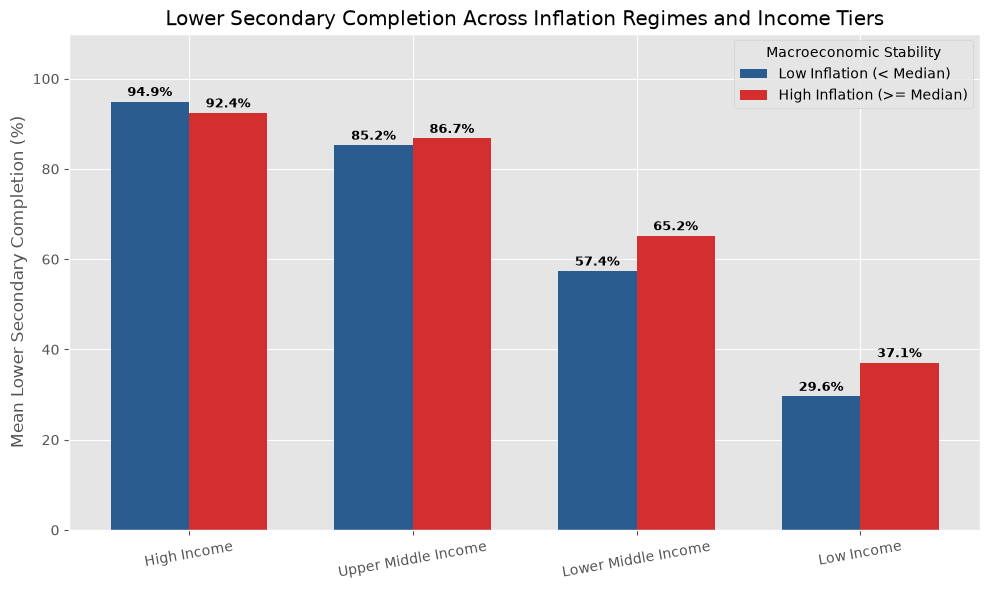

In [44]:
def compare_inflation_regimes(data_country):
    # split countries into high and low inflation regimes based on median inflation rate
    sub = data_country.dropna(subset=['Inflation_Rate_Pct']).copy()
    med_inf = sub['Inflation_Rate_Pct'].median()
    sub['Inflation_Regime'] = np.where(
        sub['Inflation_Rate_Pct'] >= med_inf,
        'High Inflation (>= Median)',
        'Low Inflation (< Median)'
    )
    return (
        sub.groupby(['Income_Level', 'Inflation_Regime'])[['Lower_Sec_Completion_Pct', 'Internet_Usage_Pct']]
        .mean()
        .unstack()
        .reindex(income_order)
        .round(2)
    )

def plot_inflation_regimes(data_country):
    # Compare completion rates across inflation regimes and income tiers
    sub_inf = data_country.dropna(subset=['Inflation_Rate_Pct']).copy()
    med_inf = sub_inf['Inflation_Rate_Pct'].median()

    sub_inf['Inflation_Regime'] = np.where(
        sub_inf['Inflation_Rate_Pct'] >= med_inf,
        'High Inflation',
        'Low Inflation'
    )

    macro_bar_data = (
        sub_inf.groupby(['Income_Level', 'Inflation_Regime'])
        ['Lower_Sec_Completion_Pct']
        .mean()
        .unstack()
        .reindex(income_order)
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(income_order))
    width = 0.35

    bars1 = ax.bar(
        x - width / 2,
        macro_bar_data['Low Inflation'],
        width,
        label='Low Inflation (< Median)',
        color='#2b5c8f'
    )
    bars2 = ax.bar(
        x + width / 2,
        macro_bar_data['High Inflation'],
        width,
        label='High Inflation (>= Median)',
        color='#d32f2f'
    )

    ax.set_xticks(x)
    ax.set_xticklabels(income_order, rotation=10)
    ax.set_ylabel('Mean Lower Secondary Completion (%)')
    ax.set_ylim(0, 110)
    ax.set_title('Lower Secondary Completion Across Inflation Regimes and Income Tiers')
    ax.legend(title='Macroeconomic Stability')

    for bar in list(bars1) + list(bars2):
        height = bar.get_height()
        ax.annotate(
            f'{height:.1f}%',
            (bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            fontsize=9,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

    return

display(compare_inflation_regimes(df_country))
plot_inflation_regimes(df_country)

For low to upper middle class countries, it can be seen that countries with higher inflation had more secondary school completion rates than lower inflation countries. A possible explanation for this could be the lack of jobs in a high-inflation market. When inflation rises, the job market often worsens, leaving young people with fewer employment options. With fewer jobs available, staying in secondary school becomes a better use of time than looking for work. Another potential explanation could be that families would choose to invest in education of their children when their currency is losing value.

## Limitations
The analysis is not without its limitations. The main limitation recognized is that the countries were all treated as equal and were not weighted by population. In this scenario, a country like Monaco has the same weight as China . These countries have a big difference in population, For more accurate data this would need to be incorporated but that goes beyond the scope of this assignment. Another limitation was the substantial amount of imputation needed in lower secondary school completion rate. Lower secondary completion had 717 missing values and income per capita had 551. These were filled by linear interpolation, then forward and backward fill, then income-group medians. 


Additional data that could have been useful in this analysis could be: Public spending on education (% of GDP), Pupil-teacher ratio and rural vs urban population share to assess further potential barriers.

## Conclusion

To answer our research question, *“What factors affect secondary school completion rates and how has it changed over the last decade?”*. Our analysis showed that national income per capita is the strongest factor. When looking at the decade long progress, lower middle and upper middle income nations made the biggest gains in completion rates, while high income nations largely stay at the same level.

Beyond just wealth, physical and digital infrastructure also play a big role. The correlation matrix and median split analysis shows that even among the the poorest nations, nations with above average internet and electricity access have better educational results. 

Macroeconomic issues like inflation showed a very weak effect on completion rates, which suggests that education is more dependant on long term structural development(internet usage & eletricity access) than short term economic changes.


Coming back to the SDG, our findings suggest that global education can't be tackled in isolation. The trends found in our analysis while not conclusive show that investment needs to be not only done in foundational economic growth (SDG8) but also in providing and improving physical & digital infrastructure (SDG 7 & 9) to support global education (SDG 4)


## Reflection

Working on this project was a great lesson in the messy reality of global data. We were really happy with how we managed to successfully pull and merge the World Bank and IMF APIs to look at education from both an infrastructure and macroeconomic angle. 

However, our biggest hurdle was definitely the missing data, especially for low income countries. To keep those nations in our analysis, we leaned heavily on interpolation and filling gaps with income group medians. Looking back, we realize this approach was a bit too aggressive. It ended up flattening out the variance in the low income bracket and probably made the 10-year progress look more stagnant than it actually was. 

If we had more time, we would run a robustness check using only the raw, non-imputed data to see if our conclusions still held up. Ultimately, we learned a lot about how much our early data-cleaning choices can unintentionally shape the final results.


## AI Use statement

AI tools were used in the completion of this assignment only as a means of reviewing project status and gaps compared to the ruberic and assignment criteria. No code was AI generated and No text was AI generated.
Gaps shown by AI were discussed within the group and if deemed valid were manually addressed and analysed.